# COVID Stringency: How Life Was Impacted Across Our Countries

Rashmi, Alex, Duy & Brisa

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.dates import MonthLocator, num2date
import altair as alt
import io
import urllib.request
import zipfile
import os
import unicodedata

alt.data_transformers.disable_max_rows() # to avoid maxrowserror in altair

DataTransformerRegistry.enable('default')

## OWID EDA
Student Name: Rashmi Kamath


**Question I am exploring:** Who got vaccinated against COVID-19, how fast, and why did some countries stall?

Smaller questions for the charts:
1. How did vaccination grow over time for each income group?
2. Did richer countries vaccinate more, and which countries break that pattern?
3. How did our group's four countries (United States, India, Vietnam, South Korea) compare?
4. How many people got a first dose but did not finish?
5. How did boosters compare with full vaccination?

### Load/Inspect OWID Data

**Source:** Our World in Data (OWID), COVID-19 compact dataset: https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv

Published online at OurWorldInData.org: https://ourworldindata.org/coronavirus

In [2]:
owid_url = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"
covid = pd.read_csv(owid_url, parse_dates=["date"])
covid.head()

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


In [3]:
print(covid.shape)
covid.info()

(629868, 61)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 629868 entries, 0 to 629867
Data columns (total 61 columns):
 #   Column                                      Non-Null Count   Dtype         
---  ------                                      --------------   -----         
 0   country                                     629868 non-null  object        
 1   date                                        629868 non-null  datetime64[ns]
 2   total_cases                                 617520 non-null  float64       
 3   new_cases                                   612628 non-null  float64       
 4   new_cases_smoothed                          611419 non-null  float64       
 5   total_cases_per_million                     617520 non-null  float64       
 6   new_cases_per_million                       612628 non-null  float64       
 7   new_cases_smoothed_per_million              611419 non-null  float64       
 8   total_deaths                                617520 non-null  

The data has 629,868 rows and 61 columns. One row is one location on one day.Most columns are numbers (float64). Only `country`, `code` and `continent` are text.

The columns I will use:

- `country` : object : country or group name
- `continent` : object : continent (empty for groups like "World")
- `date` : datetime : the day of the record
- `population` : float : number of people
- `gdp_per_capita` : float : GDP per person
- `people_vaccinated_per_hundred` : float : Total number of people who received at least one vaccine dose per 100 people in the total population.(%)
- `people_fully_vaccinated_per_hundred` : float : Total number of people who received all doses prescribed by the initial vaccination protocol per 100 people in the total population.(%)
- `total_boosters_per_hundred` : float : Total number of COVID-19 vaccination booster doses administered per 100 people in the total population.
- `new_people_vaccinated_smoothed_per_hundred` : float : Daily number of people receiving their first vaccine dose (7-day smoothed) per 100 people in the total population.

In [4]:
print("Number of locations:", covid["country"].nunique())
print("Continents:", covid["continent"].unique())
print("Date range:", covid["date"].min().date(), "to", covid["date"].max().date())

# Locations with no continent are groups, not countries
covid[covid["continent"].isna()]["country"].unique()

Number of locations: 262
Continents: ['Asia' nan 'Europe' 'Africa' 'Oceania' 'North America' 'South America']
Date range: 2020-01-01 to 2026-10-18


array(['Africa', 'Asia', 'Asia excl. China', 'England',
       'England and Wales', 'Europe', 'European Union (27)',
       'High-income countries', 'Low-income countries',
       'Lower-middle-income countries', 'North America',
       'Northern Ireland', 'Oceania', 'Scotland', 'South America',
       'Summer Olympics 2020', 'Upper-middle-income countries', 'Wales',
       'Winter Olympics 2022', 'World', 'World excl. China',
       'World excl. China and South Korea',
       'World excl. China, South Korea, Japan and Singapore'],
      dtype=object)

There are 262 locations, but some of them are groups, not countries. They have no continent, for example `World`, `High-income countries` and `European Union (27)`. If I keep them with the countries, people would be counted twice. I will remove them from the country data, but I will keep the four income groups for a separate chart.

In [5]:
vax_cols = ["people_vaccinated_per_hundred", "people_fully_vaccinated_per_hundred",
            "total_boosters_per_hundred", "new_people_vaccinated_smoothed_per_hundred"]

(covid[vax_cols].isnull().mean() * 100).round(1)

people_vaccinated_per_hundred                 87.5
people_fully_vaccinated_per_hundred           87.8
total_boosters_per_hundred                    90.7
new_people_vaccinated_smoothed_per_hundred    67.8
dtype: float64

About 88% of rows have no vaccination numbers. This makes sense for two reasons: vaccines only started in December 2020, and many countries reported their totals only once a week or once a month, not every day. So I will drop rows with no vaccination number instead of filling them in.

In [6]:
covid[vax_cols].describe().round(1)

,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_people_vaccinated_smoothed_per_hundred
count,79011.0,77011.0,58784.0,202840.0
mean,52.5,47.0,30.9,0.1
std,29.5,29.3,29.5,0.2
min,0.0,0.0,0.0,0.0
25%,26.8,19.0,1.0,0.0
50%,63.1,56.4,27.7,0.0
75%,76.7,73.1,53.8,0.1
max,112.1,110.2,140.5,11.7


In [7]:
covid[(covid["people_vaccinated_per_hundred"] > 100) | (covid["people_fully_vaccinated_per_hundred"] > 100)]["country"].unique()

array(['Cook Islands', 'Gibraltar', 'Nauru'], dtype=object)

In [8]:
covid[covid["total_boosters_per_hundred"] > 100]["country"].unique()

array(['Belgium', 'Chile', 'Gibraltar', 'Guernsey', 'Japan', 'Taiwan'],
      dtype=object)

- `people_vaccinated_per_hundred` and `people_fully_vaccinated_per_hundred` go up to about 112, which should not happen for a percentage. I checked, and these come from three very small places (Gibraltar, Nauru and the Cook Islands). This can happen when many people from outside get vaccinated there, or when the population number is out of date. The 1 million population filter in the next step removes them.
- `total_boosters_per_hundred` goes above 100 because it counts doses, and one person can get more than one booster.

### Clean the OWID data

1. Keep only real countries (rows with a continent).
2. Keep countries with more than 1 million people, so very small places do not create extreme values.
3. Keep only the columns I need, and drop rows with no vaccination number.
4. Make a separate table for the four World Bank income groups.

In [9]:
countries = covid[covid["continent"].notna()]

In [10]:
countries[countries["population"] <= 1_000_000]["country"].unique()

array(['American Samoa', 'Andorra', 'Anguilla', 'Antigua and Barbuda',
       'Aruba', 'Bahamas', 'Barbados', 'Belize', 'Bermuda', 'Bhutan',
       'Bonaire Sint Eustatius and Saba', 'British Virgin Islands',
       'Brunei', 'Cape Verde', 'Cayman Islands', 'Comoros',
       'Cook Islands', 'Curacao', 'Dominica', 'Falkland Islands',
       'Faroe Islands', 'Fiji', 'French Guiana', 'French Polynesia',
       'Gibraltar', 'Greenland', 'Grenada', 'Guadeloupe', 'Guam',
       'Guernsey', 'Guyana', 'Iceland', 'Isle of Man', 'Jersey',
       'Kiribati', 'Liechtenstein', 'Luxembourg', 'Macao', 'Maldives',
       'Malta', 'Marshall Islands', 'Martinique', 'Mayotte',
       'Micronesia (country)', 'Monaco', 'Montenegro', 'Montserrat',
       'Nauru', 'New Caledonia', 'Niue', 'Northern Mariana Islands',
       'Palau', 'Reunion', 'Saint Barthelemy', 'Saint Helena',
       'Saint Kitts and Nevis', 'Saint Lucia',
       'Saint Martin (French part)', 'Saint Pierre and Miquelon',
       'Saint Vince

In [11]:

countries = countries[countries["population"] > 1_000_000]

In [12]:
keep = ["country", "continent", "date", "population", "gdp_per_capita"] + vax_cols
vax = countries[keep].dropna(subset=["people_vaccinated_per_hundred"])


In [13]:
print(vax["date"].min(), vax["date"].max())
vax.groupby("country")["date"].max().describe()

2020-12-02 00:00:00 2024-08-12 00:00:00


count                              158
mean     2023-07-08 06:31:53.924050688
min                2021-09-27 00:00:00
25%                2023-03-13 06:00:00
50%                2023-08-02 12:00:00
75%                2023-12-10 00:00:00
max                2024-08-12 00:00:00
Name: date, dtype: object

In [14]:
income_groups = ["Low-income countries", "Lower-middle-income countries",
                 "Upper-middle-income countries", "High-income countries"]
income = covid[covid["country"].isin(income_groups)][["country", "date"] + vax_cols]
income = income.dropna(subset=["people_vaccinated_per_hundred"])

In [15]:
print("Countries:", vax["country"].nunique())
print("Rows:", len(vax))
print("Rows per country (median):", vax.groupby("country").size().median())
vax.head()

Countries: 158
Rows: 53899
Rows per country (median): 186.5


,country,continent,date,population,gdp_per_capita,people_vaccinated_per_hundred,people_fully_vaccinated_per_hundred,total_boosters_per_hundred,new_people_vaccinated_smoothed_per_hundred
418,Afghanistan,Asia,2021-02-22,40578847.0,1964.452271,0.000000,NaN,NaN,NaN
424,Afghanistan,Asia,2021-02-28,40578847.0,1964.452271,0.020208,NaN,NaN,0.003368
440,Afghanistan,Asia,2021-03-16,40578847.0,1964.452271,0.133074,NaN,NaN,0.007054
462,Afghanistan,Asia,2021-04-07,40578847.0,1964.452271,0.295721,NaN,NaN,0.007393
477,Afghanistan,Asia,2021-04-22,40578847.0,1964.452271,0.591441,NaN,NaN,0.019715


In [16]:
vax.isnull().sum()

country                                           0
continent                                         0
date                                              0
population                                        0
gdp_per_capita                                 1466
people_vaccinated_per_hundred                     0
people_fully_vaccinated_per_hundred            2973
total_boosters_per_hundred                    16405
new_people_vaccinated_smoothed_per_hundred      146
dtype: int64

After cleaning there are 158 countries. The median country has about 186 days with a vaccination number, but some have far fewer, so dates like "the day a country reached 50%" are only approximate.

### Summary table: one row per country

For each country I take the highest value reached, because these totals only go up over time.

In [17]:
owid_summary = vax.groupby("country").agg(
    continent=("continent", "first"),
    gdp_per_capita=("gdp_per_capita", "max"),
    one_dose=("people_vaccinated_per_hundred", "max"),
    fully=("people_fully_vaccinated_per_hundred", "max"),
    boosters=("total_boosters_per_hundred", "max"),
).reset_index()

owid_summary["did_not_finish"] = owid_summary["one_dose"] - owid_summary["fully"]
print(owid_summary[["one_dose", "fully", "boosters", "did_not_finish"]].describe().round(1))
owid_summary.sort_values("one_dose").head(10)

       one_dose  fully  boosters  did_not_finish
count     158.0  157.0     149.0           157.0
mean       59.1   53.6      33.5             5.5
std        25.2   25.5      30.9             5.8
min         0.3    0.3       0.0             0.0
25%        41.8   33.7       7.1             2.0
50%        64.6   57.6      28.0             4.1
75%        79.6   74.4      52.8             7.1
max        98.6   98.6     140.5            48.9


,country,continent,gdp_per_capita,one_dose,fully,boosters,did_not_finish
20,Burundi,Africa,1066.512939,0.277072,0.272658,0.002357,0.004414
155,Yemen,Asia,NaN,2.747574,2.111450,0.180324,0.636124
110,Papua New Guinea,Oceania,4456.230957,3.744128,3.147961,0.337963,0.596167
59,Haiti,North America,2677.893799,4.532458,3.184559,NaN,1.347899
85,Madagascar,Africa,1668.477051,8.904759,8.636944,0.555855,0.267815
29,Congo,Africa,6194.089844,11.528550,10.838571,0.000000,0.689979
50,Gabon,Africa,18986.474609,12.804443,10.592245,0.106634,2.212198
22,Cameroon,Africa,4945.956543,13.584352,11.570632,2.907997,2.013720
136,Syria,Asia,4579.439941,14.671913,10.499275,0.337817,4.172638
44,Equatorial Guinea,Africa,13786.393555,14.976527,11.867269,0.254886,3.109258


In [18]:
owid_summary.head()

,country,continent,gdp_per_capita,one_dose,fully,boosters,did_not_finish
0,Afghanistan,Asia,1964.452271,47.195450,45.270844,6.727495,1.924606
1,Albania,Europe,22724.292969,47.717087,45.244260,14.230054,2.472827
2,Algeria,Africa,15882.713867,17.239624,14.251447,1.265796,2.988177
3,Angola,Africa,8760.190430,46.444870,26.965265,8.606956,19.479605
4,Argentina,South America,27846.597656,91.457770,76.860214,83.054030,14.597556


In [19]:
owid_summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 158 entries, 0 to 157
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         158 non-null    object 
 1   continent       158 non-null    object 
 2   gdp_per_capita  153 non-null    float64
 3   one_dose        158 non-null    float64
 4   fully           157 non-null    float64
 5   boosters        149 non-null    float64
 6   did_not_finish  157 non-null    float64
dtypes: float64(5), object(2)
memory usage: 8.8+ KB


In [20]:
owid_summary[owid_summary.isnull().any(axis=1)]

,country,continent,gdp_per_capita,one_dose,fully,boosters,did_not_finish
18,Bulgaria,Europe,35325.531250,31.583748,15.926223,NaN,15.657525
32,Croatia,Europe,44172.042969,59.457554,57.634790,NaN,1.822764
33,Cuba,North America,NaN,97.701120,90.902530,79.501434,6.798590
38,Djibouti,Africa,7222.549805,37.074368,35.283410,NaN,1.790958
52,Georgia,Asia,25135.783203,43.599450,33.629680,NaN,9.969770
59,Haiti,North America,2677.893799,4.532458,3.184559,NaN,1.347899
77,Kyrgyzstan,Asia,7878.449219,24.965395,20.213600,NaN,4.751795
78,Laos,Asia,8872.694336,77.902405,69.088650,NaN,8.813755
117,Romania,Europe,40845.984375,28.562483,27.855442,NaN,0.707041
130,South Sudan,Africa,NaN,39.153057,38.773117,4.655783,0.379940


In [21]:
# Highest coverage
owid_summary.sort_values("one_dose", ascending=False).head(10)

,country,continent,gdp_per_capita,one_dose,fully,boosters,did_not_finish
116,Qatar,Asia,110135.695312,98.60714,98.607140,65.854610,0.000000
33,Cuba,North America,NaN,97.70112,90.902530,79.501434,6.798590
148,United Arab Emirates,Asia,69701.789062,97.54937,95.608130,50.172390,1.941240
101,Nicaragua,North America,7933.488770,95.15444,91.026825,42.975430,4.127615
115,Portugal,Europe,42576.812500,94.28189,85.530440,68.026070,8.751450
98,Nepal,Asia,5276.923828,93.83405,82.351290,34.572570,11.482760
124,Singapore,Asia,139592.609375,93.57716,92.899060,84.411550,0.678100
137,Taiwan,Asia,NaN,93.50615,88.783066,108.738440,4.723084
61,Hong Kong,Asia,68724.554688,92.68869,91.124664,97.631020,1.564026
26,Chile,South America,30863.421875,92.51003,90.523636,140.514920,1.986394


## Additional OWID EDA
Student Name: Brisa Halviatti

I used the same data as Rashmi, because much of our EDA was the same, I have included only a few extra EDA steps I performed.

I truncate the data to just the countries in question, in order to compare countries in our dataset to one another along many/multiple variables

In [22]:
covid.groupby('country', observed=True).agg(
    rows=('date', 'size'), first_date=('date', 'min'), last_date=('date', 'max'))

,rows,first_date,last_date
country,,,
Afghanistan,2483,2020-01-01,2026-10-18
Africa,2480,2020-01-04,2026-10-18
Albania,2483,2020-01-01,2026-10-18
Algeria,2483,2020-01-01,2026-10-18
American Samoa,2480,2020-01-04,2026-10-18
...,...,...,...
World excl. China and South Korea,2480,2020-01-04,2026-10-18
"World excl. China, South Korea, Japan and Singapore",2480,2020-01-04,2026-10-18
Yemen,2483,2020-01-01,2026-10-18


In [23]:
covid.columns

Index(['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed',
       'total_cases_per_million', 'new_cases_per_million',
       'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths',
       'new_deaths_smoothed', 'total_deaths_per_million',
       'new_deaths_per_million', 'new_deaths_smoothed_per_million',
       'excess_mortality', 'excess_mortality_cumulative',
       'excess_mortality_cumulative_absolute',
       'excess_mortality_cumulative_per_million', 'hosp_patients',
       'hosp_patients_per_million', 'weekly_hosp_admissions',
       'weekly_hosp_admissions_per_million', 'icu_patients',
       'icu_patients_per_million', 'weekly_icu_admissions',
       'weekly_icu_admissions_per_million', 'stringency_index',
       'reproduction_rate', 'total_tests', 'new_tests',
       'total_tests_per_thousand', 'new_tests_per_thousand',
       'new_tests_smoothed', 'new_tests_smoothed_per_thousand',
       'positive_rate', 'tests_per_case', 'total_vaccinations',
    

limit to just the countries in question

In [24]:
df = covid.loc[covid['code'].isin(['KOR', 'VNM', 'USA', 'IND'])].copy()

In [25]:
df.groupby("code")[["new_cases_smoothed_per_million", "new_deaths_smoothed_per_million"]].describe().T

code                                           IND          KOR          USA  \
new_cases_smoothed_per_million  count  2475.000000  2475.000000  1229.000000   
                                mean     12.771716   269.751934   246.427584   
                                std      36.494669   850.338256   322.558288   
                                min       0.000000     0.000000     0.000000   
                                25%       0.002906     0.000000    87.311940   
                                50%       0.103328     0.733838   160.616500   
                                75%       8.135228   100.865545   294.358860   
                                max     274.500640  7821.164600  2370.877200   
new_deaths_smoothed_per_million count  2475.000000  2475.000000  2475.000000   
                                mean      0.151321     0.280500     1.471179   
                                std       0.405904     0.816113     2.030046   
                                min       0.000000     0.000000     0.000000   
                                25%       0.000000     0.000000     0.174423   
                                50%       0.001102     0.005518     0.583502   
                                75%       0.112648     0.176563     1.896904   
                                max       2.939478     6.941118     9.978089   

code                                           VNM  
new_cases_smoothed_per_million  count  2475.000000  
                                mean     47.116354  
                                std     241.022820  
                                min       0.000000  
                                25%       0.000000  
                                50%       0.014331  
                                75%       2.688586  
                                max    2749.031700  
new_deaths_smoothed_per_million count  2475.000000  
                                mean      0.175129  
                                std       0.590481  
                                min       0.000000  
                                25%       0.000000  
                                50%       0.000000  
                                75%       0.001433  
                                max       4.105969

## OxCGRT EDA

Student Name: Alex Song

The Oxford COVID-19 Government Response Tracker (OxCGRT) is a project of the Blavatnik School of Government at the University of Oxford. Researchers reviewed government announcements and recorded, **day by day**, how governments responded to COVID-19.

We use `OxCGRT_compact_national_v1.csv`, the compact national dataset. It contains one row for each country on each day from **January 1, 2020, to December 31, 2022**.

- Data: https://github.com/OxCGRT/covid-policy-dataset
- Codebook & Variable definitions: https://github.com/OxCGRT/covid-policy-dataset/blob/main/documentation_and_codebook.md

### Load/Inspect OxCGRT Data

In [26]:
oxcgrt_url = "https://raw.githubusercontent.com/OxCGRT/covid-policy-dataset/""e7f66ee39654293b5c068efd2f195bd591dc27f6/data/OxCGRT_compact_national_v1.csv"
oxcgrt= pd.read_csv(oxcgrt_url)

# Filter to USA, IND, KOR, VNM
codes = ["USA", "IND", "KOR", "VNM"]
oxcgrt_selected = oxcgrt[oxcgrt["CountryCode"].isin(codes)].copy()

oxcgrt_selected.head()

,CountryName,CountryCode,RegionName,RegionCode,Jurisdiction,Date,C1M_School closing,C1M_Flag,C2M_Workplace closing,C2M_Flag,...,V3_Vaccine Financial Support (summary),V4_Mandatory Vaccination (summary),ConfirmedCases,ConfirmedDeaths,MajorityVaccinated,PopulationVaccinated,StringencyIndex_Average,GovernmentResponseIndex_Average,ContainmentHealthIndex_Average,EconomicSupportIndex
83296,India,IND,NaN,NaN,NAT_TOTAL,20200101,0.0,NaN,0.0,NaN,...,0,NaN,0.0,0.0,NV,0.0,0.0,0.0,0.0,0.0
83297,India,IND,NaN,NaN,NAT_TOTAL,20200102,0.0,NaN,0.0,NaN,...,0,NaN,0.0,0.0,NV,0.0,0.0,0.0,0.0,0.0
83298,India,IND,NaN,NaN,NAT_TOTAL,20200103,0.0,NaN,0.0,NaN,...,0,NaN,0.0,0.0,NV,0.0,0.0,0.0,0.0,0.0
83299,India,IND,NaN,NaN,NAT_TOTAL,20200104,0.0,NaN,0.0,NaN,...,0,NaN,0.0,0.0,NV,0.0,0.0,0.0,0.0,0.0
83300,India,IND,NaN,NaN,NAT_TOTAL,20200105,0.0,NaN,0.0,NaN,...,0,NaN,0.0,0.0,NV,0.0,0.0,0.0,0.0,0.0


Shape and time coverage - Checking how many rows and columns the four-country subset has, the date range, and whether every country has the same number of days.

In [27]:
print("Shape:", oxcgrt_selected.shape)
print("First date:", oxcgrt_selected["Date"].min())
print("Last date:", oxcgrt_selected["Date"].max())
print("\nRows per country:")
print(oxcgrt_selected["CountryName"].value_counts().sort_index())

Shape: (4384, 56)
First date: 20200101
Last date: 20221231

Rows per country:
CountryName
India            1096
South Korea      1096
United States    1096
Vietnam          1096
Name: count, dtype: int64


Sample of the data

In [28]:
oxcgrt_selected[["CountryName", "Date", "C1M_School closing",
                "C2M_Workplace closing", "C3M_Cancel public events",
                "C4M_Restrictions on gatherings", "C5M_Close public transport",
                "C6M_Stay at home requirements","C8EV_International travel controls",
                "H6M_Facial Coverings", "StringencyIndex_Average"]].sample(5, random_state=54321)

,CountryName,Date,C1M_School closing,C2M_Workplace closing,C3M_Cancel public events,C4M_Restrictions on gatherings,C5M_Close public transport,C6M_Stay at home requirements,C8EV_International travel controls,H6M_Facial Coverings,StringencyIndex_Average
100039,South Korea,20201030,1.0,1.0,1.0,3.0,0.0,1.0,2.0,3.0,51.39
191992,United States,20200711,3.0,2.0,2.0,4.0,1.0,2.0,3.0,4.0,68.98
83859,India,20210717,3.0,3.0,2.0,4.0,2.0,3.0,3.0,4.0,81.94
196826,Vietnam,20211004,2.0,2.0,2.0,3.0,2.0,0.0,3.0,3.0,64.35
192033,United States,20200821,3.0,2.0,2.0,4.0,1.0,2.0,3.0,4.0,68.98


### Data Documentation

**What one row represents:** One country on one day. There are 1,096 days (January 1, 2020 to December 31, 2022) for each of the four countries, giving us `4 × 1,096 = 4,384` rows. Every country has the same number of daily records.

**Columns:** The file has 56 columns. The letter at the beginning of each column name identifies its category:

- **ID and date:** Country name and code, region columns (empty in this compact national dataset), `Jurisdiction`, and `Date` (stored as a number like `20200415`).

- **C (Containment and closure):** School, workplace, public event, gathering, public transport, stay-at-home, internal movement, and international travel restrictions.

- **E (Economic support):** Income support and debt relief, plus monetary amounts for fiscal measures and international aid. We don't use these columns because economic policy is outside our project's focus.

- **H (Health system):** Public information campaigns, testing, contact tracing, facial coverings, vaccine eligibility, protection of the elderly, and monetary amounts for health and vaccine spending.

- **V (Vaccine program details):** Priority groups, minimum eligible ages, and vaccination mandates.

- **Flags (`_Flag`):** Indicate whether a policy applied nationwide or only to certain places or groups.

- **Summary indices (0–100):** Stringency Index, Containment and Health Index, Economic Support Index, and Government Response Index.

- **Variables not covered in this EDA:** Confirmed cases, deaths, and vaccination rates. These will come from OWID instead.

### Important variables

Most policy columns are **ordered levels**: a higher number generally means a stronger or broader policy. Here are the variables we use:

| Column | What it measures | Levels |
|---|---|---|
| `C1M_School closing` | Were schools closed? | 0 none · 1 recommended or significant operational changes · 2 some levels closed · 3 all levels closed |
| `C2M_Workplace closing` | Were workplaces closed? | 0 none · 1 recommended closure/work from home or significant operational changes · 2 some sectors closed · 3 all but essential workplaces closed |
| `C3M_Cancel public events` | Were public events cancelled? | 0 none · 1 recommended · 2 required |
| `C4M_Restrictions on gatherings` | Limits on group size | 0 none · 1 over 1,000 people · 2 101–1,000 · 3 11–100 · 4 10 or fewer |
| `C5M_Close public transport` | Was public transport closed? | 0 none · 1 recommended closure or significant service reduction · 2 required closure |
| `C6M_Stay at home requirements` | Were people told to stay home? | 0 none · 1 recommended · 2 required except essential trips · 3 required, minimal exceptions |
| `C7M_Restrictions on internal movement` | Limits on travel within the country | 0 none · 1 recommended · 2 restricted |
| `C8EV_International travel controls` | Restrictions on international arrivals | 0 none · 1 screening · 2 quarantine · 3 ban some regions · 4 ban arrivals from all regions or total border closure |
| `H2_Testing policy` | Who could get a test? | 0 none · 1 symptoms plus specific criteria · 2 anyone with symptoms · 3 open public testing, including asymptomatic people |
| `H3_Contact tracing` | Did the government trace contacts? | 0 none · 1 limited · 2 comprehensive |
| `H6M_Facial Coverings` | Mask rules | 0 none · 1 recommended · 2 required in some public spaces · 3 required in all shared spaces · 4 required outside the home at all times |
| `H7_Vaccination policy` | Who could get a vaccine? | 0 no availability · 1–3 one to three priority groups · 4 priority groups plus some additional groups · 5 universal availability |

**Summary indices (0 to 100).** OxCGRT combines individual policy measures into four indices. We use two of them:

- **Stringency Index:** Measures the strictness of government restrictions, including school and workplace closures, gathering limits, stay-at-home rules, travel restrictions, and public information campaigns (C1–C8 and H1).

- **Containment and Health Index:** Includes the Stringency Index components plus testing, contact tracing, facial coverings, vaccination policy, and protection of elderly people (H2, H3, H6, H7, and H8).

The other two, the Economic Support Index and the Government Response Index, include economic policy, which is outside the focus of our project.

**About "M", "EV", and "_Average"** (e.g., C1M, C8EV): OxCGRT recorded some policies separately for vaccinated and unvaccinated people.

- **M (Majority):** Represents the policy applying to the majority of the population, based on vaccination rates, or the policy applying to everyone when there is no distinction.
- **EV (Everyone or Vaccinated):** Used specifically for international travel controls (C8). It represents the policy applying to everyone or, when policies differ by vaccination status, vaccinated international arrivals.
- **_Average:** For the summary indices, this represents a weighted average of the vaccinated and unvaccinated index values based on vaccination rates. When weighted averages cannot be calculated, OxCGRT uses a simple average instead.

### Data Cleaning

The OxCGRT dataset is already structured as daily country-level records, so only minimal cleaning is needed for our analysis. Our steps:

1. **Keep only the columns we use** (the variables listed above plus the two indices) and drop the rest: empty region columns, `Jurisdiction` (always `NAT_TOTAL`), out-of-scope cases, deaths, and vaccination-rate columns, as well as flag, spending, and vaccine-detail columns. These unused columns contain the only blank values in the dataset.

2. **Rename** codebook column names like `C6M_Stay at home requirements` to shorter, more readable names like `stay_at_home`.

3. **Convert** `Date` from a number like `20200415` into a proper date, and add `year` and `month` columns for grouping.

4. **Recode** policy levels as whole numbers (`3` instead of `3.0`) and add a plain-English `stay_at_home_label` for easier interpretation.

5. **Keep every day.** No rows are removed, so the daily records remain complete for merging with OWID and Google Mobility data later.

In [29]:
# Steps 1-2: keep the columns we use, with short readable names
level_names = {
    "C1M_School closing": "school_closing", "C2M_Workplace closing": "workplace_closing",
    "C3M_Cancel public events": "cancel_public_events", "C4M_Restrictions on gatherings": "gathering_limits",
    "C5M_Close public transport": "close_public_transport", "C6M_Stay at home requirements": "stay_at_home",
    "C7M_Restrictions on internal movement": "internal_movement_limits",
    "C8EV_International travel controls": "international_travel_controls",
    "H2_Testing policy": "testing_policy", "H3_Contact tracing": "contact_tracing",
    "H6M_Facial Coverings": "face_coverings", "H7_Vaccination policy": "vaccination_policy",
}
index_names = {
    "StringencyIndex_Average": "stringency_index",
    "ContainmentHealthIndex_Average": "containment_health_index",
}
rename = {"CountryName": "country", "CountryCode": "country_code", "Date": "date", **level_names, **index_names}

ox_dropped = oxcgrt_selected.columns.difference(list(rename))
print(f"Dropping {len(ox_dropped)} unused columns, {oxcgrt_selected[ox_dropped].isna().any().sum()} of which contain blanks.")
print("Blank cells in the columns we keep:", oxcgrt_selected[list(rename)].isna().sum().sum())

ox = oxcgrt_selected[list(rename)].rename(columns=rename)

Dropping 39 unused columns, 25 of which contain blanks.
Blank cells in the columns we keep: 0


In [30]:
# Steps 3-4: real dates, year/month, whole-number levels, a readable label
ox["date"] = pd.to_datetime(ox["date"].astype(str), format="%Y%m%d")
ox["year"] = ox["date"].dt.year
ox["month"] = ox["date"].dt.to_period("M").dt.to_timestamp()

levels = list(level_names.values())
ox[levels] = ox[levels].astype(int)
ox["stay_at_home_label"] = ox["stay_at_home"].map(
    {0: "none", 1: "recommended", 2: "required (essentials OK)", 3: "required (few exceptions)"})

ox = ox.sort_values(["country", "date"]).reset_index(drop=True)
ox.head()

,country,country_code,date,school_closing,workplace_closing,cancel_public_events,gathering_limits,close_public_transport,stay_at_home,internal_movement_limits,international_travel_controls,testing_policy,contact_tracing,face_coverings,vaccination_policy,stringency_index,containment_health_index,year,month,stay_at_home_label
0,India,IND,2020-01-01,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2020,2020-01-01,none
1,India,IND,2020-01-02,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2020,2020-01-01,none
2,India,IND,2020-01-03,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2020,2020-01-01,none
3,India,IND,2020-01-04,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2020,2020-01-01,none
4,India,IND,2020-01-05,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,2020,2020-01-01,none


In [31]:
# Step 5 and checks: no duplicates, every day present, no blanks, values in documented ranges
all_days = pd.date_range("2020-01-01", "2022-12-31", freq="D")
print("Shape:", ox.shape)
print("Duplicate country-day rows:", ox.duplicated(["country", "date"]).sum())
print("Every country has all", len(all_days), "days:", (ox.groupby("country")["date"].nunique() == len(all_days)).all())
print("Blank cells:", ox.isna().sum().sum())
print("All indices between 0 and 100:", ox[list(index_names.values())].stack().between(0, 100).all())
ox[levels].agg(["min", "max"])

Shape: (4384, 20)
Duplicate country-day rows: 0
Every country has all 1096 days: True
Blank cells: 0
All indices between 0 and 100: True


,school_closing,workplace_closing,cancel_public_events,gathering_limits,close_public_transport,stay_at_home,internal_movement_limits,international_travel_controls,testing_policy,contact_tracing,face_coverings,vaccination_policy
min,0,0,0,0,0,0,0,0,0,0,0,0
max,3,3,2,4,2,3,2,4,3,2,4,5


**Cleaning Results**

No duplicate rows, missing days, or blank cells were found in the cleaned dataset. All policy levels fall within their documented ranges (for example, school closing: 0–3; vaccination policy: 0–5). We did not fill in or change any policy values. The cleaned dataset `ox` contains **4,384 rows**, with one row per country per day.

### Exploratory Data Analysis
1. **Country summary:** How strict were the restrictions in each country, and how long did they last?
2. **Policy shares:** Which specific measures did each country use, and how often?

In [32]:
# Shared visualization settings: one color per country, used in every chart

# Adding country colors for all charts
country_colors = {"India": "#E69F00", "South Korea": "#0072B2",
                  "United States": "#009E73", "Vietnam": "#CC79A7"}  # colorblind-friendly palette
country_order = list(country_colors)

# Adding date axis style for all charts
def style_date_axis(ax):
    """Label Jan (year underneath) and Jul; small tick and faint line for every month."""
    ax.xaxis.set_major_locator(MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_minor_locator(MonthLocator())
    ax.xaxis.set_major_formatter(plt.FuncFormatter(
        lambda x, pos: num2date(x).strftime("%b\n%Y") if num2date(x).month == 1 else num2date(x).strftime("%b")))
    ax.grid(axis="y", color="#EEEEEE")
    ax.grid(axis="x", which="major", color="#BBBBBB", linewidth=0.9)
    ax.grid(axis="x", which="minor", color="#EEEEEE", linewidth=0.6)

# Adding source (OxCGRT) for all charts
def add_source(fig, y=0.01):
    fig.text(0.99, y, "Source: Oxford COVID-19 Government Response Tracker (OxCGRT)",
             ha="right", fontsize=8, color="#555555")

In [33]:
ox_summary = ox.groupby("country").agg(
    avg_stringency=("stringency_index", "mean"),
    peak_stringency=("stringency_index", "max"),
    days_at_70_plus=("stringency_index", lambda s: (s >= 70).sum()),
    avg_containment_health=("containment_health_index", "mean"),
).round(1)
ox_summary = ox_summary.join(ox.pivot_table(index="country", columns="year", values="stringency_index")
                         .round(1).add_prefix("avg_stringency_"))
ox_summary["stringency_on_2022_12_31"] = ox[ox["date"] == "2022-12-31"].set_index("country")["stringency_index"].round(1)
ox_summary.reindex(country_order).T

country,India,South Korea,United States,Vietnam
avg_stringency,57.9,40.8,48.4,54.7
peak_stringency,100.0,82.4,75.5,96.3
days_at_70_plus,347.0,29.0,165.0,292.0
avg_containment_health,59.6,51.7,53.1,57.8
avg_stringency_2020,64.8,49.4,57.1,57.7
avg_stringency_2021,67.1,51.3,56.4,69.1
avg_stringency_2022,41.7,21.5,31.7,37.2
stringency_on_2022_12_31,28.7,11.1,28.7,23.2


In [34]:
total_days = ox["date"].nunique() 

ox_changes = pd.DataFrame({
    "pct_days_at_70_plus": (ox_summary["days_at_70_plus"] / total_days * 100).round(1).astype(str) + "%",
    "change_2020_to_2021": (ox_summary["avg_stringency_2021"] - ox_summary["avg_stringency_2020"]).map("{:+.1f}".format),
    "change_2021_to_2022": (ox_summary["avg_stringency_2022"] - ox_summary["avg_stringency_2021"]).map("{:+.1f}".format),
    "drop_from_peak_to_2022_12_31": (ox_summary["stringency_on_2022_12_31"] - ox_summary["peak_stringency"]).map("{:+.1f}".format),
}).reindex(country_order).T

ox_changes

country,India,South Korea,United States,Vietnam
pct_days_at_70_plus,31.7%,2.6%,15.1%,26.6%
change_2020_to_2021,+2.3,+1.9,-0.7,+11.4
change_2021_to_2022,-25.4,-29.8,-24.7,-31.9
drop_from_peak_to_2022_12_31,-71.3,-71.3,-46.8,-73.1


**What this shows**

- **India** was the strictest on average. It reached the maximum score of **100** and spent nearly a year (**347 days**) at a stringency of 70 or above.

- **Vietnam** reached a similar early high (about **96.3**) and spent **292 days** at a stringency of 70 or above. Its 2021 average was higher than its 2020 average, suggesting a second period of strict restrictions.

- **South Korea** had the lowest average stringency and only **29 days** at 70 or above. However, its Containment & Health average was about 11 points higher than its Stringency average (**51.7 vs. 40.9**). This was the largest gap among the four countries, suggesting greater use of health measures (testing, contact tracing, and masks) compared to restrictions such as closures.

- **The United States** had the lowest peak stringency (**75.5**), but maintained restrictions of 70 or above for **165 days**, compared to just 29 days in South Korea. It also maintained moderate restrictions for a long time, with average stringency scores in the mid-50s in both 2020 and 2021 and little change between the two years (**-0.7 points**).

- All four countries eased restrictions significantly in **2022**, but none returned to zero stringency by December 31, 2022.

## Google Mobility EDA
Student: Duy Nguyen

**Source:** Google LLC, "Google COVID-19 Community Mobility Reports", https://www.google.com/covid19/mobility/ (accessed Nov 11, 2026). Google has one big zip with every country by year; I only use the 3 Vietnam files (2020, 2021, 2022). Google stopped updating these on Oct 15, 2022.

**One row =** one place on one day. The place is either Vietnam as a whole or one of the 63 provinces/cities.

**The columns that matter:** six measures, each a % change vs a baseline:
- retail & recreation (restaurants, cafes, shopping centers)
- grocery & pharmacy
- parks
- transit stations
- workplaces
- residential (time spent at home, so it moves way less than the others)

The baseline is the median for the same weekday during Jan 3 – Feb 6, 2020. It's also only people with Google Location History turned on, so it's a sample, not everyone.

**Google's warnings** ([docs](https://www.google.com/covid19/mobility/data_documentation.html)): don't compare countries, or cities vs rural areas; don't compare single days (especially weekday vs weekend); don't compare residential with the other five; treat gaps as unknown; holidays can look like a COVID response; and the baseline doesn't account for seasons.

### Load/Inspect Data

In [35]:
# use my downloaded files if they're in a data/ folder, otherwise download google's zip
# (about 98 MB) and only pull the 3 vietnam files out of it
YEARS = (2020, 2021, 2022)
local_files = [f'data/{year}_VN_Region_Mobility_Report.csv' for year in YEARS]
if all(os.path.exists(f) for f in local_files):
    mob = pd.concat([pd.read_csv(f, parse_dates=['date']) for f in local_files], ignore_index=True)
    print('read the local files:', local_files)
else:
    url = 'https://www.gstatic.com/covid19/mobility/Region_Mobility_Report_CSVs.zip'
    with urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})) as r:
        google_zip = zipfile.ZipFile(io.BytesIO(r.read()))
    vn_files = sorted(n for n in google_zip.namelist() if n.endswith('_VN_Region_Mobility_Report.csv'))
    mob = pd.concat([pd.read_csv(google_zip.open(n), parse_dates=['date']) for n in vn_files],
                    ignore_index=True)
    print('downloaded from google:', vn_files)

print(f'{mob.shape[0]:,} rows x {mob.shape[1]} columns, '
      f'{mob["date"].min():%b %d, %Y} to {mob["date"].max():%b %d, %Y}')
mob.sample(5, random_state=5310)

downloaded from google: ['2020_VN_Region_Mobility_Report.csv', '2021_VN_Region_Mobility_Report.csv', '2022_VN_Region_Mobility_Report.csv']
62,308 rows x 15 columns, Feb 15, 2020 to Oct 15, 2022


,country_region_code,country_region,sub_region_1,sub_region_2,metro_area,iso_3166_2_code,census_fips_code,place_id,date,retail_and_recreation_percent_change_from_baseline,grocery_and_pharmacy_percent_change_from_baseline,parks_percent_change_from_baseline,transit_stations_percent_change_from_baseline,workplaces_percent_change_from_baseline,residential_percent_change_from_baseline
3844,VN,Vietnam,Ca Mau,NaN,NaN,VN-59,NaN,ChIJez-heqBJoTERs-aysVPn-a8,2020-02-22,-15.0,-15.0,-10.0,-21.0,-16.0,7.0
33882,VN,Vietnam,Lam Dong,NaN,NaN,VN-35,NaN,ChIJfdvzWSYTcTERbPVUX9_SWrs,2021-08-15,-65.0,-35.0,-55.0,-76.0,-36.0,8.0
4077,VN,Vietnam,Ca Mau,NaN,NaN,VN-59,NaN,ChIJez-heqBJoTERs-aysVPn-a8,2020-10-12,-33.0,-12.0,-33.0,-24.0,-2.0,3.0
17085,VN,Vietnam,Tây Ninh,NaN,NaN,VN-37,NaN,ChIJMXJO1JFCCzERzWzchde8giQ,2020-05-25,-13.0,10.0,-62.0,15.0,24.0,3.0
59122,VN,Vietnam,Son La,NaN,NaN,VN-05,NaN,ChIJ1R093JBZMjERezgPalpkLVg,2022-09-28,12.0,50.0,23.0,-4.0,NaN,12.0


In [36]:
# column types and how many non-null values each column has
mob.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62308 entries, 0 to 62307
Data columns (total 15 columns):
 #   Column                                              Non-Null Count  Dtype         
---  ------                                              --------------  -----         
 0   country_region_code                                 62308 non-null  object        
 1   country_region                                      62308 non-null  object        
 2   sub_region_1                                        61334 non-null  object        
 3   sub_region_2                                        0 non-null      float64       
 4   metro_area                                          0 non-null      float64       
 5   iso_3166_2_code                                     61334 non-null  object        
 6   census_fips_code                                    0 non-null      float64       
 7   place_id                                            62308 non-null  object        
 8   date  

In [37]:
# summary stats for the six measures (% change from baseline), all places and days together
mob.filter(like='_percent_change_from_baseline').describe().round(1)

,retail_and_recreation_percent_change_from_baseline,grocery_and_pharmacy_percent_change_from_baseline,parks_percent_change_from_baseline,transit_stations_percent_change_from_baseline,workplaces_percent_change_from_baseline,residential_percent_change_from_baseline
count,61632.0,58970.0,61037.0,56502.0,38982.0,61941.0
mean,-14.1,3.3,-7.7,-19.0,-9.5,-0.8
std,24.4,26.9,35.3,30.1,24.2,10.6
min,-97.0,-97.0,-96.0,-97.0,-93.0,-46.0
25%,-26.0,-12.0,-30.0,-39.0,-21.0,-10.0
50%,-14.0,2.0,-15.0,-19.0,-6.0,1.0
75%,-1.0,18.0,10.0,-2.0,7.0,7.0
max,145.0,268.0,361.0,197.0,62.0,56.0


In [38]:
# which columns are empty or only have one value, and how many rows are the whole country
# (no province name) vs the provinces
national_rows = mob['sub_region_1'].isna()
print('empty columns:     ', [c for c in mob.columns if mob[c].isna().all()])
print('one value only:    ', [c for c in mob.columns if mob[c].nunique() == 1])
print(f'national rows:      {national_rows.sum()} (one per day)')
print(f'province rows:      {(~national_rows).sum():,} for {mob["sub_region_1"].nunique()} provinces '
      f'and {mob["iso_3166_2_code"].nunique()} province codes')
print('repeated place-days:', mob.duplicated(['sub_region_1', 'date']).sum())

# some provinces are missing whole days (no row at all)
n_days = mob['date'].nunique()
rows_per_province = mob[~national_rows].groupby('sub_region_1').size()
short = (n_days - rows_per_province)[lambda gap: gap > 0]
print(f'province-days with no row: {short.sum()} ({short.to_dict()})')

# province names are written different ways: with accents, without, some with 'Province' on the end
names = pd.Series(mob['sub_region_1'].dropna().unique())
print('accented names:    ', names[~names.map(str.isascii)].head(5).tolist())
print("'Province' suffix: ", names[names.str.endswith(' Province')].tolist())

empty columns:      ['sub_region_2', 'metro_area', 'census_fips_code']
one value only:     ['country_region_code', 'country_region']
national rows:      974 (one per day)
province rows:      61,334 for 63 provinces and 63 province codes
repeated place-days: 0
province-days with no row: 28 ({'Bắc Kạn Province': 15, 'Dien Bien': 5, 'Ha Giang': 1, 'Lai Chau': 7})
accented names:     ['Bắc Kạn Province', 'Bình Định', 'Bình Thuận', 'Cần Thơ', 'Hà Nam']
'Province' suffix:  ['Bắc Kạn Province', 'Bac Ninh Province', 'Phu Tho Province', 'Quang Binh Province']


In [39]:
# % of rows with no value, by year, for the national row and for the provinces
categories = [c for c in mob.columns if c.endswith('_percent_change_from_baseline')]
missing = (mob.assign(year=mob['date'].dt.year,
                      level=national_rows.map({True: 'national', False: 'provinces'}))
              .groupby(['level', 'year'])[categories]
              .apply(lambda rows: rows.isna().mean().mul(100).round(1))
              .rename(columns=lambda c: c.replace('_percent_change_from_baseline', '')))
last_workplaces = mob.loc[mob['workplaces_percent_change_from_baseline'].notna(), 'date'].max()
print(f'last day with a workplaces value: {last_workplaces:%b %d, %Y}')
missing

last day with a workplaces value: Oct 19, 2021


retail_and_recreation  grocery_and_pharmacy  parks  \
level     year                                                       
national  2020                    0.0                   0.0    0.0   
          2021                    0.0                   0.0    0.0   
          2022                    0.0                   0.0    0.0   
provinces 2020                    3.3                   7.9    3.9   
          2021                    0.0                   4.1    0.2   
          2022                    0.0                   4.5    2.4   

                transit_stations  workplaces  residential  
level     year                                             
national  2020               0.0         0.0          0.0  
          2021               0.0        20.0          0.0  
          2022               0.0       100.0          0.0  
provinces 2020              13.0         1.1          1.5  
          2021               7.4        20.0          0.1  
          2022               8.1       100.0          0.2

In [40]:
# check 1: Tet (Lunar New Year) looks like a lockdown. national values in the week around
# Lunar New Year 2021 (Feb 12) vs the week before
nat_raw = mob[national_rows].set_index('date')[categories].rename(
    columns=lambda c: c.replace('_percent_change_from_baseline', ''))
pd.DataFrame({'Feb 1-7, 2021': nat_raw.loc['2021-02-01':'2021-02-07'].mean(),
              'Feb 10-16, 2021 (Tet)': nat_raw.loc['2021-02-10':'2021-02-16'].mean()}).round(1)

,"Feb 1-7, 2021","Feb 10-16, 2021 (Tet)"
retail_and_recreation,-12.3,-25.7
grocery_and_pharmacy,14.6,1.9
parks,-18.1,20.7
transit_stations,-12.4,-37.3
workplaces,-10.7,-69.3
residential,-8.0,-3.9


In [41]:
# check 2: is 0 actually 'normal' for vietnam? average for a calm stretch with no lockdown and
# few cases (Oct to Dec 2020)
nat_raw.loc['2020-10-01':'2020-12-31'].mean().round(1).to_frame('Oct-Dec 2020 average')

,Oct-Dec 2020 average
retail_and_recreation,-15.4
grocery_and_pharmacy,2.5
parks,-22.1
transit_stations,-6.4
workplaces,6.6
residential,-5.7


**What I found**
- The national row is basically complete. Only workplaces has gaps, and it stops completely after Oct 19, 2021.
- All 63 provinces are there and nothing is duplicated, but 28 province-days are just missing (Bac Kan 15, Lai Chau 7, Dien Bien 5, Ha Giang 1).
- 3 columns are totally empty.
- Province names are messy (some with accents, some without, 4 end in "Province"), so I match on the ISO code instead.
- The province rows have some gaps where Google didn't have enough data, mostly in transit and grocery.

Two things to watch out for:
- **Tết looks like a lockdown.** In the Lunar New Year week of 2021, workplace visits were 69% below baseline vs 11% the week before. That's the holiday, not COVID rules, so I'll mark Tết on charts.
- **0 isn't "normal" for Vietnam.** Even in calm late 2020, shop visits were ~15% below baseline and time at home ~6% below. The baseline weeks include the Tết 2020 rush and the holiday, so I compare against the calm late-2020 level instead of 0.

### Clean Data

- drop the empty / one-value columns
- shorten the six column names (e.g. `retail_and_recreation_percent_change_from_baseline` → `retail`)
- one plain name per province (no accents, no "Province"), checked against the ISO code; the national row becomes "Vietnam"
- leave gaps as missing, like Google says
- add a 7-day average for plots, since single days jump around between weekdays and weekends

In [42]:
def plain_name(name):
    # 'Bắc Kạn Province' -> 'Bac Kan'
    name = name.removesuffix(' Province').replace('Đ', 'D').replace('đ', 'd')
    return ''.join(ch for ch in unicodedata.normalize('NFKD', name) if not unicodedata.combining(ch))


short_names = {'retail_and_recreation_percent_change_from_baseline': 'retail',
               'grocery_and_pharmacy_percent_change_from_baseline': 'grocery',
               'parks_percent_change_from_baseline': 'parks',
               'transit_stations_percent_change_from_baseline': 'transit',
               'workplaces_percent_change_from_baseline': 'workplaces',
               'residential_percent_change_from_baseline': 'residential'}
MEASURES = list(short_names.values())

mob_clean = (mob.rename(columns=short_names)
                .assign(place=lambda d: d['sub_region_1'].map(plain_name, na_action='ignore').fillna('Vietnam'),
                        code=lambda d: d['iso_3166_2_code'].fillna('VN'))
                [['place', 'code', 'date'] + MEASURES])

# every code should have exactly one name and every name one code
print(f'{mob_clean["place"].nunique()} places (Vietnam + provinces); '
      f'one name per code: {(mob_clean.groupby("code")["place"].nunique() == 1).all()}; '
      f'one code per name: {(mob_clean.groupby("place")["code"].nunique() == 1).all()}')

# vietnam as a whole, smoothed with a centered 7-day average, plus the calm late-2020 level
nat = mob_clean[mob_clean['place'] == 'Vietnam'].set_index('date')[MEASURES]
nat_7d = nat.rolling(7, center=True, min_periods=7).mean()
calm_nat = nat.loc['2020-10-01':'2020-12-31'].mean()
mob_clean.sample(5, random_state=5310)

64 places (Vietnam + provinces); one name per code: True; one code per name: True


,place,code,date,retail,grocery,parks,transit,workplaces,residential
3844,Ca Mau,VN-59,2020-02-22,-15.0,-15.0,-10.0,-21.0,-16.0,7.0
33882,Lam Dong,VN-35,2021-08-15,-65.0,-35.0,-55.0,-76.0,-36.0,8.0
4077,Ca Mau,VN-59,2020-10-12,-33.0,-12.0,-33.0,-24.0,-2.0,3.0
17085,Tay Ninh,VN-37,2020-05-25,-13.0,10.0,-62.0,15.0,24.0,3.0
59122,Son La,VN-05,2022-09-28,12.0,50.0,23.0,-4.0,NaN,12.0


### Quick Plots

In [43]:
# quick look at all six measures for vietnam as a whole (7-day average). the five visit measures
# share one scale; residential (time at home) gets its own because google says not to compare it
long = nat_7d.reset_index().melt('date', var_name='measure', value_name='change')
visits = alt.Chart(long[long['measure'] != 'residential']).mark_line(color='#333333', strokeWidth=1).encode(
    x=alt.X('date:T', title=None),
    y=alt.Y('change:Q', title=None),
    row=alt.Row('measure:N', title=None, sort=MEASURES[:-1], header=alt.Header(labelAngle=0, labelAlign='left'))
).properties(width=620, height=70)
home = alt.Chart(long[long['measure'] == 'residential']).mark_line(color='#333333', strokeWidth=1).encode(
    x=alt.X('date:T', title=None),
    y=alt.Y('change:Q', title=None)
).properties(width=620, height=70, title='residential = time at home (own scale)')
alt.vconcat(visits, home).properties(title=alt.TitleParams(
    'Every kind of trip fell in April 2020 and summer 2021, and time at home went up',
    subtitle='Vietnam as a whole, % change from Google\'s baseline, centered 7-day average'))

alt.VConcatChart(...)

### EDA Summary
**What stands out**
- Movement dropped hard twice: April 2020 (nationwide stay-home order) and summer 2021 (Delta wave, worst Jul–Sep). Every kind of trip fell and time at home went up.
- In between it stayed near the late-2020 level (except Da Nang's lockdown in summer 2020 and Tết). By mid-2022 shop and park visits were above Google's baseline, transit still below.
- Summer 2021 was regional: the 22 provinces I found under a stay-home order had the 22 biggest drops in shop visits (52–81 points), the next one only 44, and lots of northern/central provinces barely moved. Google says don't compare cities vs rural areas, but both groups have both, so I'm only leaning on the gap between the groups.
- The orders went where the outbreak was worst, so this data alone can't tell the rules apart from fear of the virus.

**Does it need more data?** Yes. Google only shows what people did, not what the rules were or how bad the outbreak was, so it needs the stringency index + case counts from OWID (that's Plot 1). There's no dataset of order dates by province, so I put that list together by hand from news reports. For the group: Google has India, the US and South Korea too, but Google says don't compare countries, so each country should be compared with its own calm period.

**Chart ideas:** rules + cases + shop visits on one time axis (Plot 1), a cleaner version of the province dot plot, and visits the week before vs the first week of each stay-home order.

# Brainstorming

Then as a group, brainstorm a list of at least 5 visualizations that could be made with this collective information. Come up with a one-sentence statement or question that the graphic would address. For each of the visualizations, answer the following questions. Your answer can be in the form of a mock-up if you have ready-to-plot data.

### Plot 1 - Duy (OWID + Mobility Data)

In [44]:
# 1. Our World in Data: Vietnam's rows, cleaned
# read straight from the URL, keeping only the columns this chart needs
cols = ['country', 'date', 'new_cases', 'new_deaths', 'new_cases_per_million',
        'stringency_index', 'people_vaccinated_per_hundred']
owid = covid
vn = owid[owid['country'] == 'Vietnam'].sort_values('date').reset_index(drop=True)

# real reports stop on the last day with a new case; every later new_cases value is a filler 0
last_case = vn.loc[vn['new_cases'] > 0, 'date'].max()
keep = {'date': 'date', 'new_cases': 'cases', 'new_deaths': 'deaths',
        'new_cases_per_million': 'cases_per_million', 'stringency_index': 'stringency',
        'people_vaccinated_per_hundred': 'pct_first_dose'}
vn_clean = (vn.loc[vn['date'] <= last_case, list(keep)]
              .rename(columns=keep)
              .dropna(subset=['cases', 'deaths'], how='all')   # the first days of 2020 have no figures
              .set_index('date'))

# new cases per million as a centered 7-day median: a median keeps a one-day backlog of earlier
# cases (such as 28,000 Binh Duong cases logged on Nov 23, 2021) from lifting a whole week
cases_7d = vn_clean['cases_per_million'].rolling(7, center=True, min_periods=7).median()
stringency = vn_clean['stringency']
first_dose = vn_clean['pct_first_dose'].ffill()   # reported irregularly, so carried forward

# 2. Google mobility: Vietnam as a whole 
# Google has no API: read its regional ZIP into memory and take the three Vietnam files
with urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})) as response:
    google_zip = zipfile.ZipFile(io.BytesIO(response.read()))
vn_files = sorted(name for name in google_zip.namelist()
                  if name.endswith('_VN_Region_Mobility_Report.csv'))
print('Google files read:', vn_files)
mob = pd.concat([pd.read_csv(google_zip.open(name), parse_dates=['date']) for name in vn_files],
                ignore_index=True)

# the national row is the one with no province name (one row per day); retail and recreation
# counts visits to shops, restaurants and cafes
nat = (mob[mob['sub_region_1'].isna()].set_index('date')
       ['retail_and_recreation_percent_change_from_baseline'].rename('retail'))

# a 7-day average centered on each day, because single days jump between weekdays and weekends
nat_7d = nat.rolling(7, center=True, min_periods=7).mean()

# Google's baseline (Jan 3 to Feb 6, 2020) includes Tet, so 0 is not 'normal' for Vietnam:
# the calm late-2020 average is the reference level instead
calm = nat.loc['2020-10-01':'2020-12-31'].mean()

# 3. The chart's data: Feb 15, 2020 (Google's first day) to Dec 31, 2021 
# the window ends before the Omicron wave (2,656 new cases per million a day on Mar 14, 2022),
# which would flatten both 2021 waves on a linear scale; cutting it off at the top would be a
# scale break on a connected line (Week 4 slide 8)
START, END = '2020-02-15', '2021-12-31'
a_data = (pd.DataFrame({'stringency': stringency, 'cases': cases_7d, 'retail': nat_7d})
            .sort_index().loc[START:END].rename_axis('date').reset_index())

# the stay-home orders: Apr 1-15, 2020 nationwide (Pham et al., 2021, The Lancet Global Health),
# and Jul 9 to Sep 30, 2021, from Ho Chi Minh City's order (Viet Nam News) to the day before
# its Oct 1 reopening (Tuoi Tre News). Each band covers its last day; ypix places each red name
orders = pd.DataFrame({
    'start': pd.to_datetime(['2020-04-01', '2021-07-09']),
    'end': pd.to_datetime(['2020-04-15', '2021-09-30']),
    'label': ['nationwide stay-home order', 'stay-home orders in the south and Hanoi'],
    'ypix': [16, 2]})
orders['band_end'] = orders['end'] + pd.Timedelta(days=1)
danang = pd.DataFrame({'date': pd.to_datetime(['2020-07-28']),   # Da Nang lockdown (Pham et al., 2021)
                       'label': ['Da Nang lockdown'], 'ypix': [16]})

# notes at the lowest point of visits in each summer, with the index on the same day
lows = [nat_7d.loc['2020-07-15':'2020-09-15'].idxmin(), nat_7d.loc['2021-07-01':'2021-09-30'].idxmin()]
notes_data = pd.DataFrame({'date': lows, 'retail': nat_7d[lows].to_numpy()})
notes_data['label'] = [f'index {stringency[day]:.0f}, visits {-nat_7d[day]:.0f}% below' for day in lows]

# the two late-2021 case highs: during the summer orders, and after they ended
peak_days = [cases_7d.loc['2021-08-01':'2021-09-30'].idxmax(), cases_7d.loc['2021-11-01':'2021-12-31'].idxmax()]
peaks_data = pd.DataFrame({'date': peak_days, 'cases': cases_7d[peak_days].to_numpy()})
peaks_data['label'] = peaks_data['cases'].map(lambda value: f'{value:.0f}')

# Vietnam's first-dose share in the months after the orders ended
dose_note = pd.DataFrame({'date': [pd.Timestamp('2021-10-01')],
                          'label': [f"first dose {first_dose['2021-10-01']:.0f}% → {first_dose['2021-12-31']:.0f}%"]})

print(f'calm late-2020 level: {calm:.1f}%')
print(notes_data[['date', 'label']].to_string(index=False))
print('case highs:', dict(zip(peaks_data['date'].dt.strftime('%b %d, %Y'), peaks_data['label'])))
print(dose_note['label'][0])

# 4. The chart: three strips on one date axis instead of a second y-axis (Week 5 slide 26)
RED, INK, REF, GUIDE = '#b2182b', '#333333', '#555555', '#8c8c8c'   # red only for the orders
W, INDEX_H, CASES_H, VISITS_H = 850, 48, 52, 150

date_scale = alt.Scale(domain=[alt.DateTime(year=2020, month='Feb', date=15),
                               alt.DateTime(year=2021, month='Dec', date=31)])
# every third month, with the year under the first tick (April 2020) and under each January
date_axis = alt.Axis(tickCount={'interval': 'month', 'step': 3}, labelAngle=0, grid=False,
                     labelExpr="[timeFormat(datum.value, '%b'), month(datum.value) == 0 || "
                               "(year(datum.value) == 2020 && month(datum.value) == 3) ? "
                               "timeFormat(datum.value, '%Y') : '']")


def a_x(field, axis=date_axis):
    # every layer shares one date scale and axis, because Altair drops or merges the axis when
    # layers disagree; axis=None hides it in the two upper strips
    return alt.X(f'{field}:T', title=None, scale=date_scale, axis=axis)


def strip_label(text, x=4, y=2, align='left', baseline='top'):
    # each strip's label sits inside the plot instead of a title above it
    return alt.Chart(pd.DataFrame({'text': [text]})).mark_text(
        align=align, baseline=baseline, fontSize=11, color=REF).encode(
        x=alt.value(x), y=alt.value(y), text='text:N')


def bands(axis):
    return alt.Chart(orders).mark_rect(color=RED, opacity=0.12).encode(
        x=a_x('start', axis), x2='band_end:T')


def danang_line(top, bottom, axis):
    return alt.Chart(danang).mark_rule(color=RED, strokeDash=[3, 3]).encode(
        x=a_x('date', axis), y=alt.value(top), y2=alt.value(bottom))


# the rules (stringency index)
index_y = alt.Y('stringency:Q', title=None, scale=alt.Scale(domain=[0, 100]),
                axis=alt.Axis(values=[0, 100], labelFlush=True, gridColor='#eeeeee'))
strip_index = alt.layer(
    bands(None),
    danang_line(0, INDEX_H, None),
    alt.Chart(a_data).mark_line(color=REF, strokeWidth=1.3, interpolate='step-after').encode(
        x=a_x('date', None), y=index_y),
    strip_label('Rules: stringency index', x=W - 4, y=INDEX_H - 2, align='right', baseline='bottom'),
).properties(width=W, height=INDEX_H)

# reported cases, on a linear scale from zero, so the late-2021 rise reads against the summer wave
cases_y = alt.Y('cases:Q', title=None, scale=alt.Scale(domain=[0, 200]),
                axis=alt.Axis(values=[0, 100, 200], labelFlush=True, gridColor='#eeeeee'))
peaks = alt.Chart(peaks_data).encode(x=a_x('date', None), y=cases_y)
strip_cases = alt.layer(
    bands(None),
    danang_line(16, CASES_H, None),   # starts below the strip's label
    alt.Chart(a_data).mark_line(color=REF, strokeWidth=1.3).encode(x=a_x('date', None), y=cases_y),
    peaks.mark_circle(color=INK, size=30, opacity=1),
    peaks.mark_text(align='right', baseline='middle', dx=-6, dy=-4, fontSize=10, color=REF).encode(
        text='label:N'),
    strip_label('Reported new cases per million, Vietnam as a whole (7-day median)'),
).properties(width=W, height=CASES_H)

# shop and restaurant visits, with the date axis; the dotted line is the calm late-2020 level
visits_y = alt.Y('retail:Q', title=None, scale=alt.Scale(domain=[-100, 20]),
                 axis=alt.Axis(values=[-75, -50, -25, 0], labelExpr="datum.label + '%'",
                               grid=True, gridColor='#eeeeee'))
calm_data = pd.DataFrame({'retail': [calm], 'label': ['calm late-2020 level']})
notes = alt.Chart(notes_data).encode(x=a_x('date'), y=visits_y)
order_names = alt.Chart(pd.concat([orders.rename(columns={'start': 'date'})[['date', 'label', 'ypix']],
                                   danang]))
strip_visits = alt.layer(
    bands(date_axis),
    danang_line(30, VISITS_H, date_axis),   # starts below the red names at the top
    alt.Chart(calm_data).mark_rule(color=GUIDE, strokeDash=[1, 2], strokeWidth=1.2).encode(y=visits_y),
    alt.Chart(calm_data).mark_text(align='right', baseline='bottom', dy=-3, fontSize=10,
                                   color=REF).encode(x=alt.value(W - 4), y=visits_y, text='label:N'),
    alt.Chart(a_data).mark_line(color=INK, strokeWidth=1.5).encode(x=a_x('date'), y=visits_y),
    notes.mark_circle(color=INK, size=30, opacity=1),
    notes.mark_text(align='left', baseline='top', dx=6, dy=6, fontSize=10, color=REF).encode(
        text='label:N'),
    order_names.mark_text(align='left', baseline='top', dx=3, fontSize=10, color=RED).encode(
        x=a_x('date'), y=alt.Y('ypix:Q', scale=None), text='label:N'),
    alt.Chart(dose_note).mark_text(align='left', baseline='top', dx=3, fontSize=10, color=REF).encode(
        x=a_x('date'), y=alt.value(94), text='label:N'),
    strip_label('Shop and restaurant visits, % change from baseline (7-day average)'),
).properties(width=W, height=VISITS_H)

panel_a = (
    alt.vconcat(strip_index, strip_cases, strip_visits, spacing=4)
    .properties(title=alt.TitleParams(
        ['Shop visits in Vietnam were lowest when stay-home orders applied,',
         'but this data cannot say whether the orders or fear of the virus kept people home'],
        subtitle=['Red: stay-home orders. Ends Dec 31, 2021, before Omicron. Sources: Google COVID-19 Community '
                  'Mobility Reports; Oxford tracker, cases and first doses',
                  'via Our World in Data; order dates: Pham et al. (2021), Viet Nam News, Tuoi Tre News'],
        anchor='start', fontSize=17, subtitleFontSize=12, offset=16))
    .configure(font='Helvetica Neue, Arial, sans-serif')
    .configure_view(stroke=None)
    .configure_axis(labelFontSize=11, labelColor='#333333', domainColor='#999999', tickColor='#999999')
    .configure_title(subtitleColor='#555555')
)
panel_a

Google files read: ['2020_VN_Region_Mobility_Report.csv', '2021_VN_Region_Mobility_Report.csv', '2022_VN_Region_Mobility_Report.csv']
calm late-2020 level: -15.4%
      date                      label
2020-08-03 index 80, visits 25% below
2021-08-26 index 73, visits 74% below
case highs: {'Sep 02, 2021': '132', 'Dec 21, 2021': '162'}
first dose 34% → 78%


alt.VConcatChart(...)

**Question:** Did people in Vietnam go out less when stay-home orders applied, and did visits fall again when cases rose after the orders ended?

Discussion:
* Which variables would you use to show this? Do you need to compute new variables, filter, or do other manipulations to show this?
    - I use two datasets:
        - **Our World in Data:** `date`, `stringency_index`, `new_cases_per_million` and `people_vaccinated_per_hundred`.
        - **Google Mobility:** `date` and `retail_and_recreation_percent_change_from_baseline` (shop and restaurant visits), from the national row.
    - Manipulations:
        - Filter Our World in Data to Vietnam and cut it at the last real case report, because every later zero is filler.
        - Keep Google's national row, the one with no province name.
        - Smooth both series: a centered 7-day average for visits, and a centered 7-day median for cases, so one-day backlogs don't lift a whole week.
        - Compute a calm late-2020 average (Oct–Dec 2020) as the reference level, because Google's baseline includes Tết, so 0 is not normal for Vietnam.
        - Carry the first-dose share forward between its irregular reports.
        - Join the two sources by date and keep Feb 15, 2020 to Dec 31, 2021, which ends before Omicron and keeps the 2021 waves readable.
        - Build a small table of stay-home order dates by hand from Pham et al. (2021) and news reports.
        - Find the summer lows in visits and the two late-2021 case highs to label on the chart.
* Which encodings would you map to which variables?
    - **x-axis (position):** `date`, shared by all three strips so the rules, cases and visits line up in time.
    - **y-axis (position), one per strip:**
        - Top strip: `stringency_index`, drawn as a step line because the rules change in steps.
        - Middle strip: new cases per million (7-day median).
        - Bottom strip: shop and restaurant visits, as % change from baseline (7-day average).
    - **Color:** red marks only the stay-home orders: shaded bands for the order periods and a dashed line for the Da Nang lockdown. Everything else is grey.
    - **Reference line:** a dotted grey line at the calm late-2020 level in the visits strip.
    - **Points and text:**
        - Dots with labels mark the two summer lows (index and visits) and the two late-2021 case highs.
        - A grey text note gives the first-dose share (34% → 78%).
        - The red order names sit directly on the bands instead of in a legend.
* What chart type (line, scatter, bar, etc) would be most effective to show this?
    - Three stacked line charts (small multiples) that share one time axis: the rules, then cases, then visits. A line chart fits because every variable is a time series, and the questions are about when things changed and whether they changed together.
    - Stacking the strips works better than a dual-axis chart, because each variable keeps its own scale and the comparison stays fair (Week 5 slide 26). The index is drawn as a step line, since the rules change in steps rather than smoothly. Shaded bands mark the stay-home order periods on all three strips, so the reader can see what the rules, cases and visits did during each order.
* What other design considerations (color, scales, titles, labels, ticks) would you need to make? If you don't know yet, that's ok, but give a best guess.
    - **Color:** red appears only on the stay-home orders (the bands, the dashed Da Nang line and the order names); everything else is grey.
    - **Scales:**
        - Cases use a linear scale starting at zero.
        - The window ends Dec 31, 2021, before Omicron ( variant (version) of the COVID-19 virus). Clipping the Omicron peak would be a scale break (Week 4 slide 8), and a log scale would hide the late-2021 comparison and confuse readers (Week 4 slides 11–12).
        - Visits are read against a calm late-2020 reference line, because Google's 0 is not normal for Vietnam.
    - **Titles:** a takeaway title that states the finding, and a subtitle that lists the sources and says where the window ends. There are no separate titles over each strip.
    - **Labels:** each strip's label sits inside the plot, and labels go directly on the data (order names, the summer lows, the case highs, the first-dose note) instead of in a legend (Week 3 slide 16).
    - **Ticks:** a date tick every 3 months, with the year shown once, and ticks at both ends of the cases scale (Week 4 slide 22). Light gridlines keep the eye on the data.
    - **Layout:** the three strips sit close together on one shared date axis (Week 5 slide 49). The chart is static, with no tooltips (Week 3 slide 16).

### Plot 2 - Rashmi (OWID Data)

In [45]:
our_countries = ["United States", "India", "Vietnam", "South Korea"]
scatter_data = owid_summary.dropna(subset=["gdp_per_capita"])

points = alt.Chart(scatter_data).mark_circle(size=70, opacity=0.75).encode(
    alt.X("gdp_per_capita:Q", title="GDP per person (US dollars, log scale)",
          scale=alt.Scale(type="log", domain=[800, 150000], nice=False), axis=alt.Axis(format="$~s", values=[1000, 2000, 4000, 8000, 16000, 32000, 64000, 128000])),
    alt.Y("one_dose:Q", title="% with at least one dose", scale=alt.Scale(domain=[0, 100])),
    alt.Color("continent:N", title="Continent", scale=alt.Scale(scheme="tableau10")),
    tooltip=["country", "continent", alt.Tooltip("gdp_per_capita:Q", format="$,.0f"), alt.Tooltip("one_dose:Q", format=".1f")]
)

labels = alt.Chart(scatter_data[scatter_data["country"].isin(our_countries)]).mark_text(
    align="left", dx=7, fontSize=11, fontWeight="bold"
).encode(x="gdp_per_capita:Q", y="one_dose:Q", text="country")

chart1 = (points + labels).properties(width=600, height=380,
    title=alt.TitleParams("Richer countries vaccinated more, but with many exceptions",
                          subtitle="Each dot is one country (over 1 million people). Hover for the name."))
chart1

alt.LayerChart(...)

Question: Did richer countries vaccinate more?

Discussion:
* Which variables would you use to show this? Do you need to compute new variables, filter, or do other manipulations to show this?
    - The variables are 'gdp_per_capita', 'one_dose', 'country', and 'continenet'. We show all valid countries (filtering out data rows that aggregate many countries together), and plot GDP and Dose against one another on a scatter plot
* Which encodings would you map to which variables?
    - Position (x = GDP per person (log scale), y = % with at least one dose), color = continent
* What chart type (line, scatter, bar, etc) would be most effective to show this?
    - A scatter plot is the most effective way to show this since this allows us to make a direction comparision (using position) of how the variables of GDP per capita and vaccination rates move
* What other design considerations (color, scales, titles, labels, ticks) would you need to make? If you don't know yet, that's ok, but give a best guess.
    - I use log scale since GDP per person goes from about \$1,000 to over \$100,000. On a normal scale, most countries would be squeezed on the left side. Continent is encoded to color, so we can make general observations about the known groups of countries; with our group's specific countries labeled

### Plot 3 - Rashmi (OWID Data)

In [46]:
four_summary = owid_summary[owid_summary["country"].isin(our_countries)]
four_boost = four_summary[["country", "fully", "boosters"]].melt(id_vars="country", var_name="measure", value_name="per_100")
four_boost["measure"] = four_boost["measure"].replace({
    "fully": "Fully vaccinated (people)",
    "boosters": "Booster doses"})

boost_bars = alt.Chart(four_boost).mark_bar().encode(
    alt.X("country:N", title=None, sort=our_countries, axis=alt.Axis(labelAngle=0)),
    alt.XOffset("measure:N", sort=["Fully vaccinated (people)", "Booster doses"]),
    alt.Y("per_100:Q", title="Per 100 people", scale=alt.Scale(domain=[0, 100])),
    alt.Color("measure:N", title=None, sort=["Fully vaccinated (people)", "Booster doses"], scale=alt.Scale(range=["#08519c", "#fd8d3c"])),
    tooltip=["country", "measure", alt.Tooltip("per_100:Q", format=".1f")]
)
boost_values = boost_bars.mark_text(dy=-6, fontSize=10).encode(text=alt.Text("per_100:Q", format=".0f"), color=alt.value("black"))

chart4 = (boost_bars + boost_values).properties(width=520, height=320,
    title=alt.TitleParams("South Korea gave the most boosters; India gave the fewest",
                          subtitle="Highest value reported for each country"))
chart4

alt.LayerChart(...)

Discussion:
* Which variables would you use to show this? Do you need to compute new variables, filter, or do other manipulations to show this?
    - 'country', 'measure' (where 'measure' captures Fully Vaccinated people, and those who recevied a Booster dose). This required much manipulation, specifically aggregating to one value per country and creating cumulative measures where the highest reported value is the latest total. Then, the data had to be reshaped using melt() so the two measures can share one row. 
* Which encodings would you map to which variables?
    - Position (x = each measure per country, y = value per 100 people)
    - Color, a redundant encoding to differentiate the two measures sharing X axis per country
    - Length, to demonstrate the value of each measure
    - Text, a redundant encoding to echo the length's specific value
* What chart type (line, scatter, bar, etc) would be most effective to show this?
    - This example is a grouped bar chart, we're comparing two quantities across multiple countries; both measures are per 100 people so they share the same axis
* What other design considerations (color, scales, titles, labels, ticks) would you need to make? If you don't know yet, that's ok, but give a best guess.
    - Color blind safe colors are used, the scales are the same, and a descriptive title is present. We can clearly see which countries have the largest gaps between a fully vaccianted population and those that only received one booster. 

### Plot 4 - Alex (Oxford Data)
Policy shares: which measures did each country use, and how often?
Each bar shows the percentage of days (2020–2022) a country spent at each policy level. Lighter colors represent weaker or no restrictions, while darker colors represent stronger restrictions.

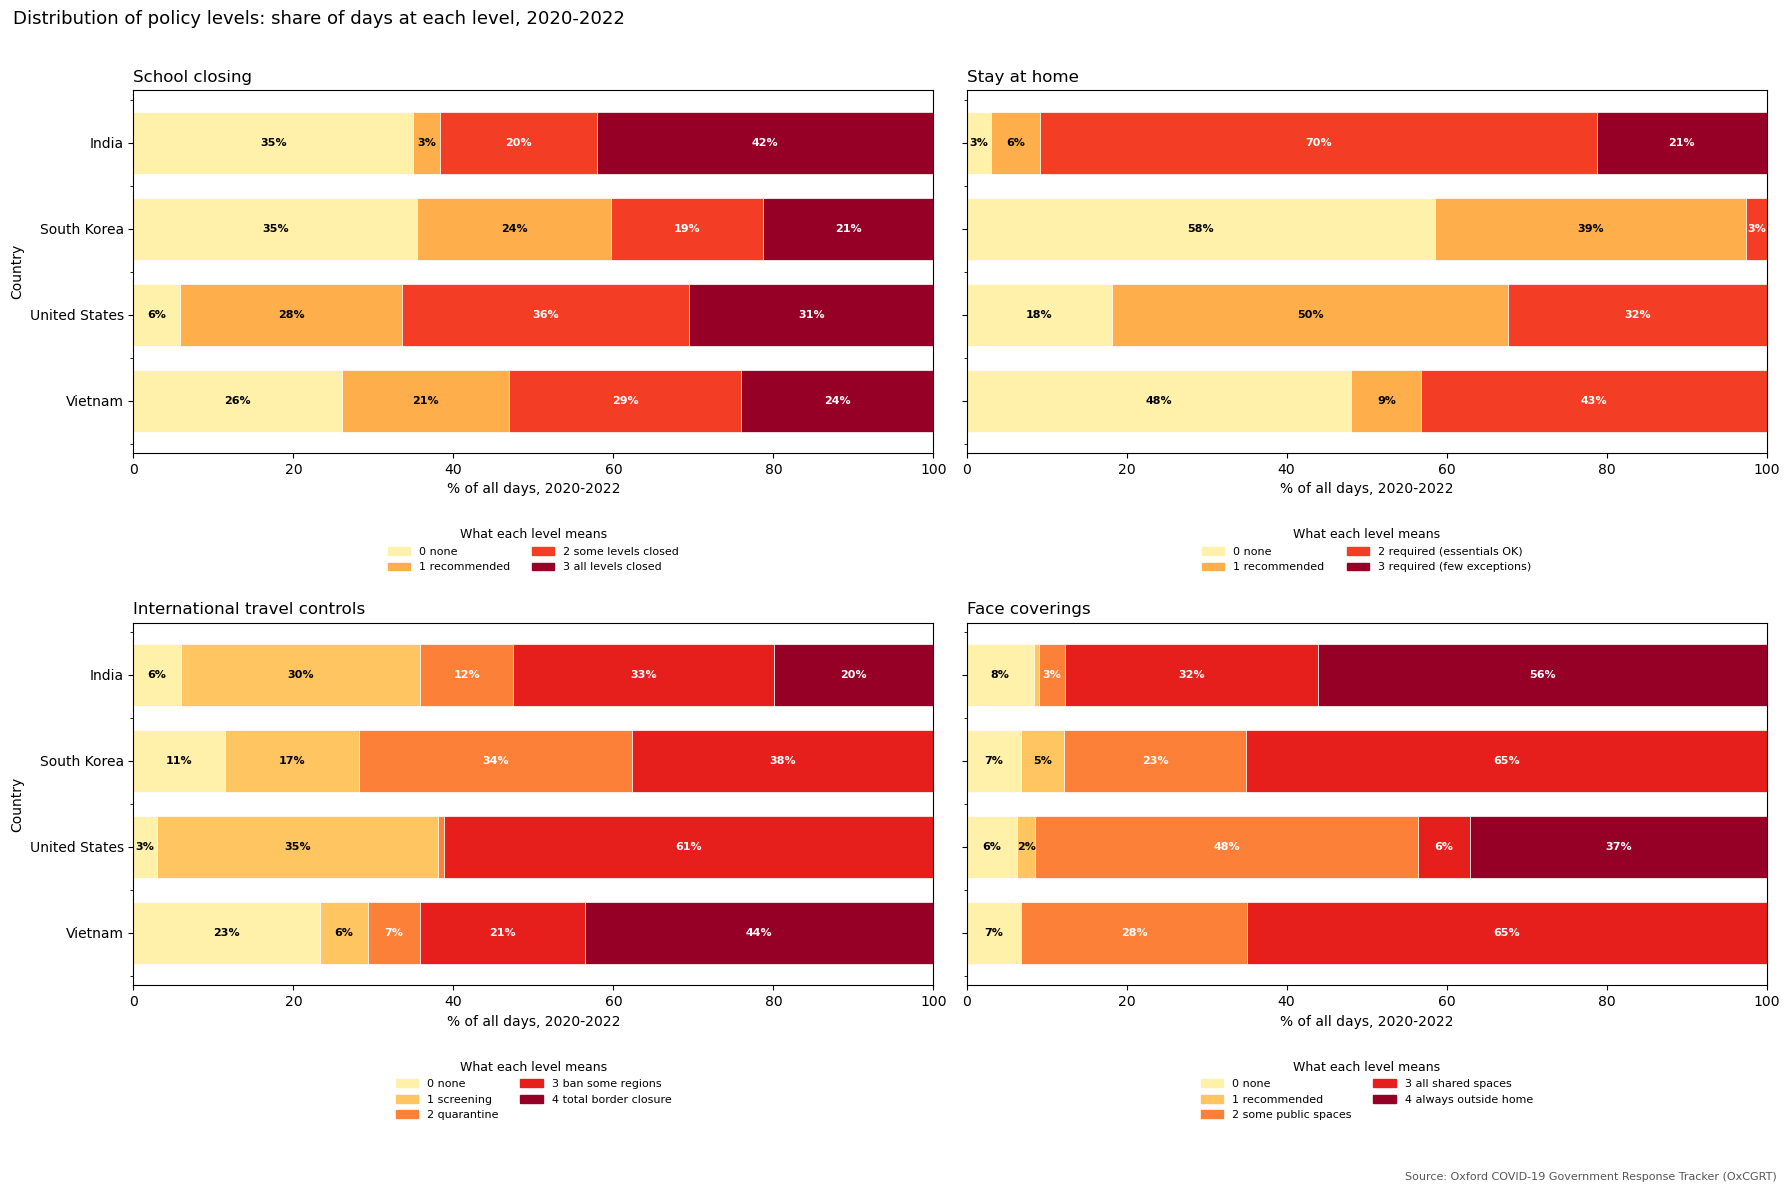

In [47]:
level_meanings = {
    "school_closing": ["0 none", "1 recommended", "2 some levels closed", "3 all levels closed"],
    "stay_at_home": ["0 none", "1 recommended", "2 required (essentials OK)", "3 required (few exceptions)"],
    "international_travel_controls": ["0 none", "1 screening", "2 quarantine", "3 ban some regions",
                                      "4 total border closure"],
    "face_coverings": ["0 none", "1 recommended", "2 some public spaces", "3 all shared spaces",
                       "4 always outside home"],
}

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
for ax, (col, labels) in zip(axes.flat, level_meanings.items()):
    share = (pd.crosstab(ox["country"], ox[col], normalize="index").mul(100)
               .reindex(index=country_order[::-1], columns=range(len(labels)), fill_value=0))
    colors = plt.cm.YlOrRd([0.1 + 0.85 * i / (len(labels) - 1) for i in range(len(labels))])
    share.plot(kind="barh", stacked=True, ax=ax, width=0.72, color=colors,
               edgecolor="white", linewidth=0.5, legend=False)

    for i, country in enumerate(share.index):
        left = 0
        for level in share.columns:
            width = share.loc[country, level]
            if width >= 2:
                ax.text(left + width / 2, i, f"{width:.0f}%", ha="center", va="center",
                        fontsize=8, color="black" if level <= 1 else "white", fontweight="bold")
            left += width

    ax.set_title(col.replace("_", " ").capitalize(), loc="left", fontsize=12)
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of all days, 2020-2022")
    ax.set_ylabel("Country")
    handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in colors]
    ax.legend(handles, labels, title="What each level means", fontsize=8, title_fontsize=9,
              loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)

fig.suptitle("Distribution of policy levels: share of days at each level, 2020-2022",
             x=0.01, ha="left", fontsize=13)
add_source(fig, y=0.005)
plt.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

**What this shows**

This shows that two countries with similar Stringency scores can get there through very different measures, so the index alone hides important differences. For example, **India and Vietnam** both had high stringency levels, but India had stay-at-home rules on **91%** of days, compared to **43%** for Vietnam. Meanwhile, Vietnam fully closed its borders on **44%** of days, compared to **20%** for India. 

- **Stay-at-home rules** show the clearest contrast. India had some form of stay-at-home rule on about **9 in 10 days (91%)**, while South Korea had one on only about **3%** of days. Vietnam alternated between having no rule and requiring people to stay home.

- **School closures:** India had the most days with all schools closed, while the United States had some level of school restrictions on almost every day (**over 90%**), mostly involving partial closures.

- **International travel:** Vietnam spent about **44%** of days with its borders fully closed, compared to about **20%** for India. South Korea and the U.S. never fully closed their borders.

- **Face coverings**: this was among the longest-lasting measures, every country had some form of mask policy on more than **90%** of days.


### Plot 5 - Alex (Oxford Data)
Stringency by Country

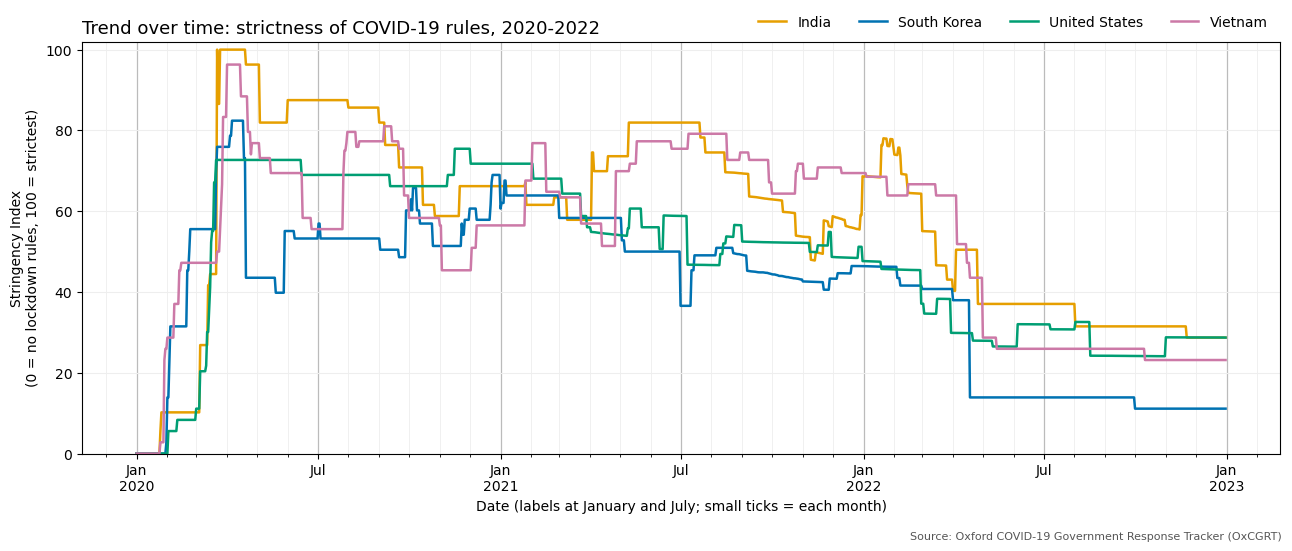

In [48]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for country in country_order:
    g = ox[ox["country"] == country]
    ax.plot(g["date"], g["stringency_index"], label=country, color=country_colors[country], linewidth=1.8)

ax.set_ylim(0, 102)
ax.set_ylabel("Stringency Index\n(0 = no lockdown rules, 100 = strictest)")
ax.set_xlabel("Date (labels at January and July; small ticks = each month)")
ax.set_title("Trend over time: strictness of COVID-19 rules, 2020-2022", loc="left", fontsize=13)
ax.legend(ncol=4, loc="lower right", bbox_to_anchor=(1, 1), frameon=False)
style_date_axis(ax)
add_source(fig)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

**Question:** How did COVID-19 government restrictions change over time across the four countries, and how did their responses differ?

**Which variables would you use? Do you need to compute new variables, filter, or do other manipulations?**
- **OxCGRT (this notebook):** `date`, `country`, `stringency_index`.
- **Manipulations:**
  - Filter to the four countries: USA, IND, KOR, and VNM.
  - Use the daily Stringency Index to compare government restrictions over time.
  - Keep the full period, January 1, 2020 – December 31, 2022.

**Which encodings would you map to which variables?**
- **x-position:** Date.
- **y-position:** Stringency Index (0–100).
- **Color:** Country, using the same colorblind-friendly palette as the charts above.

**What chart type would be most effective?** A multi-line time-series chart showing all four countries on the same axes. This makes it easy to compare when restrictions increased, decreased, and how government responses differed over time.

**Other design considerations (color, scales, titles, labels, ticks):**
- Keep the y-axis on a fixed 0–100 scale.
- Use distinct, colorblind-friendly colors for each country.
- Date ticks at January and July, with small monthly ticks.
- Include a descriptive title and a source note listing OxCGRT.
- Keep the legend clear and consistent with the country colors used in the other charts.

### Plot 6 - Brisa (OWID Data)

In [49]:
df_vax_chart = df[['country', 'date', 'total_vaccinations_per_hundred']]

In [50]:
vax_chart = alt.Chart(df_vax_chart).mark_line(strokeWidth=1.5).encode(
        x=alt.X('date:T', title=None, axis=alt.Axis(format='%Y', tickCount='year')),
        y=alt.Y('total_vaccinations_per_hundred:Q', title=None),
        color=alt.Color('country:N',
                  scale=alt.Scale(domain=list(country_colors),
                                  range=list(country_colors.values())),
                  title='Country'),
    ).properties(title='Total vaccinations per hundred', width=700, height=250)

vax_chart

alt.Chart(...)

Question: How did vaccination rates compare, country by country, over time?

Discussion:
* Which variables would you use to show this? Do you need to compute new variables, filter, or do other manipulations to show this?
    - date, country, and total_vaccinations_per_hundred from OWID, filtered to Korea, Vietnam, the United States and India. We are counting doses, not people, so the lines surpass 100. 
* Which encodings would you map to which variables?
    - Position (x = date, y = total vaccinations per hundred)
    - Line color is encoded with country, so we can tell the position of each relative to one another
* What chart type (line, scatter, bar, etc) would be most effective to show this?
    - Because we are comparing data over time, a line chart is appropriate
* What other design considerations (color, scales, titles, labels, ticks) would you need to make? If you don't know yet, that's ok, but give a best guess.
    - This is a preliminary visual to better understand that data. We can see that the reporting has missing days, since not every country reported data every day. India and Vietnam both show dashed gaps in their respective line charts.

### Plot 7 - Brisa (OWID Data)

In [51]:
df_cases_chart = df[['country', 'date', 'new_cases_smoothed_per_million']]

In [52]:
cases_chart = alt.Chart(df_cases_chart).mark_line(strokeWidth=1.5).encode(
        x=alt.X('date:T', title=None, axis=alt.Axis(format='%Y', tickCount='year')),
        y=alt.Y('new_cases_smoothed_per_million:Q', title=None),
        color=alt.Color('country:N',
                  scale=alt.Scale(domain=list(country_colors),
                                  range=list(country_colors.values())),
                  title='Country'),
    ).properties(title='New cases per million (smoothed)', width=700, height=250)
cases_chart 

alt.Chart(...)

Question: How did COVID case rates compare, country by country, over time?

Discussion:
* Which variables would you use to show this? Do you need to compute new variables, filter, or do other manipulations to show this?
    - date, country, and new_cases_smoothed_per_million from OWID, filtered to Korea, Vietnam, the United States and India. The variable is already transformed to a rate per million, which adjusts for population; it is also already smoothed, which removes the noise.
* Which encodings would you map to which variables?
    - Position (x = date, y = new cases per million)
    - Line color is encoded with country, using the same colors as the other charts, so each country's waves can be told apart and compared
* What chart type (line, scatter, bar, etc) would be most effective to show this?
    - Because we are tracking a rate over time, a line chart is appropriate. It shows when each wave happened and how high it peaked.
* What other design considerations (color, scales, titles, labels, ticks) would you need to make? If you don't know yet, that's ok, but give a best guess.
    - This is a preliminary visual to better understand the data. South Korea's spike in early 2022 is so tall that it flattens everything else. India's 2021 wave barely shows up even though it was its worst period. A log scale, or one small chart per country with its own y-axis, would make each country's waves readable.

## Additional Discussion

### Alex: OxCGRT Summary
**What we found so far**
1. All four countries tightened restrictions around March–April 2020, but followed different paths. India and Vietnam had repeated strict periods, the U.S. maintained moderate restrictions, and South Korea generally had lower stringency.

2. South Korea had the fewest days at high stringency (29 days) and the largest gap between its Stringency and Containment & Health averages, suggesting a greater emphasis on health measures relative to closure-style restrictions.

3. Policy approaches differed: India relied more heavily on stay-at-home rules, while Vietnam relied more heavily on border closures. Mask policies lasted for more than 90% of days in all four countries.

4. All four countries eased restrictions substantially in 2022, but none returned to zero by the end of the dataset.

### Brisa: Seeking more data
We know that we are narrowing down on a theme of Stringency: intent vs outcome. Rashmi analyzed how different countries vaccination rates compared to one another; specifically initial boosters vs fully vaccinated status. Alex charted the measures of stringency across the countries we're focusing on. Duy used mobility data to see how effective high stringency periods were in Vietnam. I have put everyone's data together (including my EDA/Visuals of Rashmi's data), and am now seeking additional measures we can include to help paint the picture of how stringency did/didn't limit people's lives during COVID. Some items I am exploring include:
* Finding access to Google trends, can we see how searches for 'tinder' (exists in all four countries) or other key words related to dating, changed with stringency in each country?
* Connect data from YouGov Covid Behavior tracker to analyze how behavior changed by country (https://github.com/YouGov-Data/covid-19-tracker)